# Demo 8 - Reinforcement Learning

## Tutorial: Q Learning no ambiente FrozenLake

### MBA em AI Engineering & Multi Agents - Machine Learning Foundations & Classic Models.

### Prof. Dr. Ahirton Lopes (profahirton.lopes@fiap.com.br)

Ref. - https://gymnasium.farama.org/environments/toy_text/frozen_lake/

# Q* Learning com FrozenLake 4x4

Neste Notebook, implementaremos um agente <b>que reproduz o desafio FrozenLake.</b>

![texto alternativo](https://www.gymlibrary.dev/_images/frozen_lake.gif)

O objetivo deste jogo é <b>passar do estado inicial (S) para o estado objetivo (G)</b> andando apenas sobre peças congeladas (F) e evitando buracos (H). No entanto, o gelo é escorregadio, **então você nem sempre se moverá na direção pretendida (ambiente estocástico)**

## Pré-requisitos 🏗️

Antes de mergulhar no notebook **você precisa entender**:
- Os fundamentos da aprendizagem por reforço (MC, TD, hipótese de recompensas...)
- Q-aprendizagem

## Etapa 1: Instalando as dependências no Google Colab

In [36]:
!pip install gymnasium
!pip install numpy

## Etapa 0: Importando as dependências 📚

Usamos 3 bibliotecas:

- `Numpy` para nosso Qtable
- `Gymnasium` para nosso ambiente FrozenLake
- `Random` para gerar números aleatórios

In [37]:
import numpy as np
import gymnasium as gym
import random
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

## Passo 1: Criando o ambiente 🎮

- Aqui criaremos o ambiente FrozenLake 8x8.
- Gymnasium é uma biblioteca <b> composta por diversos ambientes que podemos usar para treinar nossos agentes.</b>
- No nosso caso optamos por usar Frozen Lake.

In [38]:
env = gym.make("FrozenLake-v1", desc=None, map_name="4x4", is_slippery=True, render_mode="rgb_array")

## Etapa 2: Criando a tabela Q e inicializando-a 🗄️

- Agora, vamos criar nossa Q-table, para saber de quantas linhas (estados) e colunas (ações) precisamos, precisamos calcular o action_size e o state_size
- Gymnasium nos fornece uma maneira de fazer isso: `env.action_space.n` e `env.observation_space.n`

In [39]:
action_size = env.action_space.n
state_size = env.observation_space.n

In [40]:
# Create our Q table with state_size rows and action_size columns (64x4)
qtable = np.zeros((state_size, action_size))
print(qtable)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


## Etapa 3: Criando os hiperparâmetros ⚙️

- Aqui, especificaremos os hiperparâmetros

In [41]:
total_episodes = 10000       # Total episodes
learning_rate = 0.7          # Learning rate
max_steps = 99               # Max steps per episode
gamma = 0.95                 # Discounting rate

# Exploration parameters
epsilon = 1.0                 # Exploration rate
max_epsilon = 1.0             # Exploration probability at start
min_epsilon = 0.01            # Minimum exploration probability
decay_rate = 0.001            # Exponential decay rate for exploration prob


![texto alternativo](https://miro.medium.com/v2/resize:fit:1400/1*tyIE_430xbBRzrrjUdYLQw.png)


## Etapa 4: O algoritmo de aprendizagem Q 🧠

- Agora implementamos o algoritmo de aprendizagem Q:


In [42]:
# List of rewards
rewards = []

# 2 For life or until learning is stopped
for episode in range(total_episodes):
    # Reset the environment
    state, _ = env.reset()
    state = int(state)
    step = 0
    done = False
    total_rewards = 0

    for step in range(max_steps):
        # 3. Choose an action a in the current world state (s)
        ## First we randomize a number
        exp_exp_tradeoff = random.uniform(0, 1)

        ## If this number > greater than epsilon --> exploitation (taking the biggest Q value for this state)
        if exp_exp_tradeoff > epsilon:
            action = np.argmax(qtable[state,:])
            #print(exp_exp_tradeoff, "action", action)

        # Else doing a random choice --> exploration
        else:
            action = env.action_space.sample()
            #print("action random", action)


        # Take the action (a) and observe the outcome state(s') and reward (r)
        new_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Update Q(s,a):= Q(s,a) + lr [R(s,a) + gamma * max Q(s',a') - Q(s,a)]
        # qtable[new_state,:] : all the actions we can take from new state
        qtable[state, action] = qtable[state, action] + learning_rate * (reward + gamma * np.max(qtable[new_state, :]) - qtable[state, action])

        total_rewards += reward

        # Our new state is state
        state = new_state

        # If done (if we're dead) : finish episode
        if done:
            break

    # Reduce epsilon (because we need less and less exploration)
    epsilon = min_epsilon + (max_epsilon - min_epsilon)*np.exp(-decay_rate*episode)
    rewards.append(total_rewards)


print ("Pontuação no tempo: " +  str(sum(rewards)/total_episodes))
print(qtable)

Pontuação no tempo: 0.3504
[[2.40524642e-01 5.04324102e-02 4.54269801e-02 4.92827131e-02]
 [1.26877675e-02 1.52274079e-02 4.24536741e-03 5.38702884e-02]
 [1.45681726e-02 2.37696292e-02 3.05935744e-02 2.34849118e-02]
 [4.40558385e-03 9.90508259e-03 1.02598336e-02 2.39865341e-02]
 [3.91974037e-01 5.91633670e-03 2.01152235e-02 6.65304685e-03]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [9.64926801e-04 3.87983616e-04 2.14878761e-01 9.42906139e-04]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [2.90121708e-02 5.59936270e-02 2.34387284e-02 5.74024372e-01]
 [4.16439056e-02 6.44524022e-01 2.37434359e-02 6.46594114e-03]
 [7.11174981e-01 1.02710372e-02 9.91759523e-03 1.73700122e-02]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [9.24854278e-02 3.54033692e-02 7.20939455e-01 2.18149083e-01]
 [3.70740643e-01 9.31763818e-01 7.52683393e-01 3.09697008e-01]
 [0.00000000e+00 0.00000000e

## Etapa 5: Usando nossa tabela Q para jogar FrozenLake! 👾

- Após 10.000 episódios, nossa tabela Q pode ser usada como uma "folha de dicas" para jogar FrozenLake"
- Ao executar este celular você poderá ver nosso agente jogando FrozenLake.

Caímos em um Obstáculo ☠️
Número de passos 13


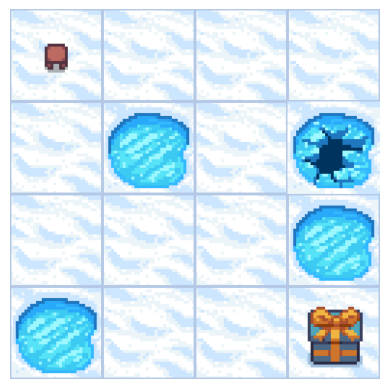

In [43]:
for episode in range(5):
    state, info = env.reset()
    state = int(state)
    step = 0
    done = False
    max_steps = 100
    frames = [] # To store frames for animation

    print("****************************************************")
    print(f"EPISODIO {episode}")

    for step in range(max_steps):
        # Render the environment and save the frame
        frame = env.render()
        frames.append(frame)

        # Take the action (index) that have the maximum expected future reward given that state
        action = np.argmax(qtable[state,:])

        new_state, reward, terminated, truncated, _ = env.step(action)

        done = terminated or truncated

        if done:
            # Render the final frame
            frame = env.render()
            frames.append(frame)

            # Display the collected frames as an animation
            for img in frames:
                clear_output(wait=True)
                plt.imshow(img)
                plt.axis('off')
                display(plt.gcf())
            clear_output(wait=True) # Clear the last displayed image

            if new_state == 15:
                print("Chegamos no Objetivo 🏆")
            else:
                print("Caímos em um Obstáculo ☠️")

            print(f"Número de passos {step}")
            break
        state = int(new_state)
env.close()

## Visualizando o progresso do treinamento

Vamos plotar as recompensas totais por episódio para ver como o agente aprendeu ao longo do tempo.

********Average reward per thousand episodes********

100 :  0.0
200 :  0.01
300 :  0.01
400 :  0.01
500 :  0.02
600 :  0.01
700 :  0.05
800 :  0.060000000000000005
900 :  0.04
1000 :  0.07
1100 :  0.04
1200 :  0.07
1300 :  0.07
1400 :  0.07
1500 :  0.09
1600 :  0.08
1700 :  0.09
1800 :  0.07
1900 :  0.09
2000 :  0.08
2100 :  0.17
2200 :  0.16
2300 :  0.09999999999999999
2400 :  0.11999999999999998
2500 :  0.19000000000000003
2600 :  0.20000000000000004
2700 :  0.20000000000000004
2800 :  0.25000000000000006
2900 :  0.25000000000000006
3000 :  0.3300000000000001
3100 :  0.2700000000000001
3200 :  0.38000000000000017
3300 :  0.3200000000000001
3400 :  0.26000000000000006
3500 :  0.34000000000000014
3600 :  0.3000000000000001
3700 :  0.45000000000000023
3800 :  0.3100000000000001
3900 :  0.38000000000000017
4000 :  0.26000000000000006
4100 :  0.4300000000000002
4200 :  0.4200000000000002
4300 :  0.45000000000000023
4400 :  0.23000000000000007
4500 :  0.2800000000000001
4600 :  0.40000000

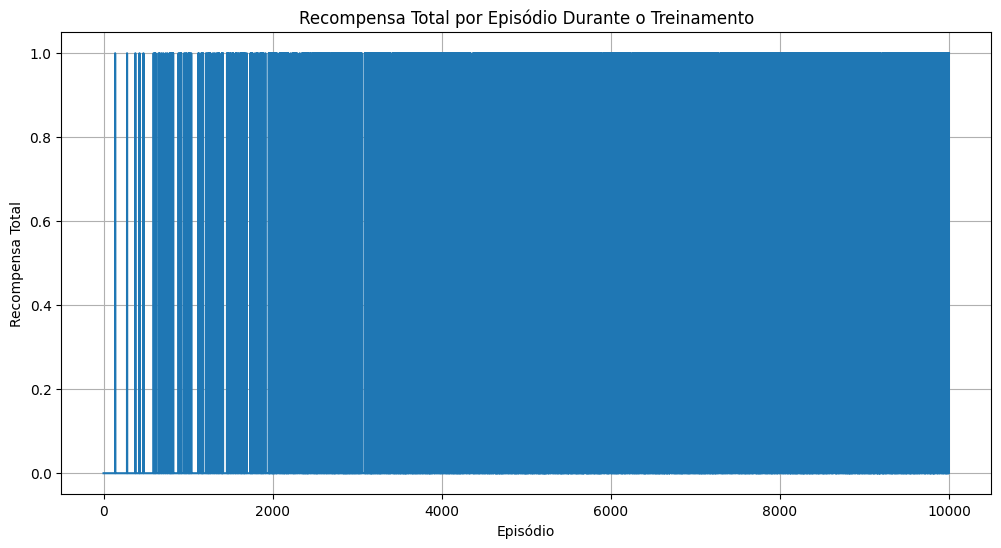

In [44]:
import matplotlib.pyplot as plt

# Calculate the average rewards for every 100 episodes
rewards_per_thousand_episodes = np.split(np.array(rewards),total_episodes/100)
count = 100

print("********Average reward per thousand episodes********\n")
for r in rewards_per_thousand_episodes:
    print(count, ": ", str(sum(r/100)))
    count += 100

# Plotting the rewards
plt.figure(figsize=(12, 6))
plt.plot(rewards)
plt.xlabel('Episódio')
plt.ylabel('Recompensa Total')
plt.title('Recompensa Total por Episódio Durante o Treinamento')
plt.grid(True)
plt.show()